/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/embedding.py:97: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

Epoch 1/7
254/254 ━━━━━━━━━━━━━━━━━━━━ 178s 677ms/step - accuracy: 0.7279 - loss: 0.6377 - val_accuracy: 0.9138 - val_loss: 0.2465
Epoch 2/7
254/254 ━━━━━━━━━━━━━━━━━━━━ 203s 681ms/step - accuracy: 0.9295 - loss: 0.1978 - val_accuracy: 0.9124 - val_loss: 0.2388
Epoch 3/7
254/254 ━━━━━━━━━━━━━━━━━━━━ 172s 677ms/step - accuracy: 0.9597 - loss: 0.1159 - val_accuracy: 0.9097 - val_loss: 0.2855
Epoch 4/7
254/254 ━━━━━━━━━━━━━━━━━━━━ 171s 674ms/step - accuracy: 0.9759 - loss: 0.0697 - val_accuracy: 0.9121 - val_loss: 0.3308
Epoch 5/7
254/254 ━━━━━━━━━━━━━━━━━━━━ 201s 668ms/step - accuracy: 0.9817 - loss: 0.0522 - val_accuracy: 0.9092 - val_loss: 0.3806
Epoch 6/7
254/254 ━━━━━━━━━━━━━━━━━━━━ 170s 671ms/step - accuracy: 0.9878 - loss: 0.0352 - val_accuracy: 0.8979 - val_loss: 0.4381
Epoch 7/7
254/254 ━━━━━━━━━━━━━━━━━━━━ 170s 669ms/step - accuracy: 0.9871 - loss: 0.0358 - val_accuracy: 0.9031 - val_loss: 0.4968
1269/1269 ━━━━━━━━━━━━━━━━━━━━ 54s 42ms/step
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 37ms/ste

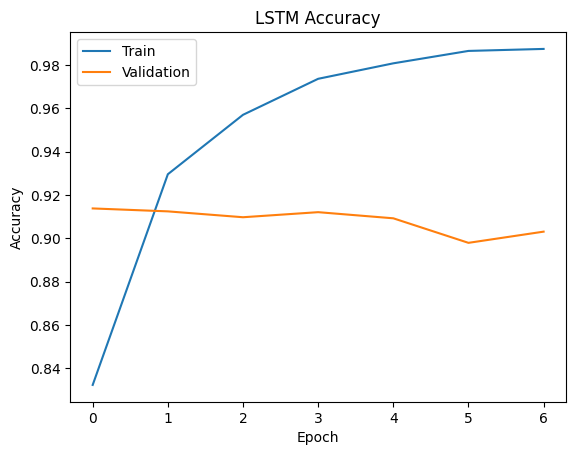

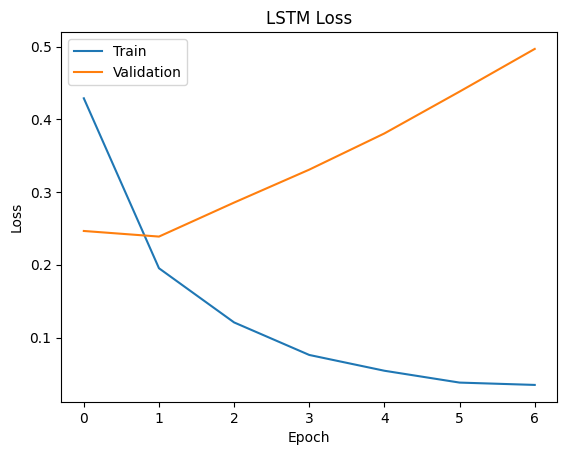

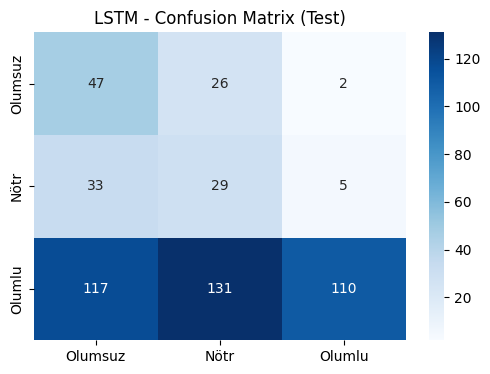

/tmp/ipython-input-2285998651.py:183: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=test_pred_raw, palette="cool")


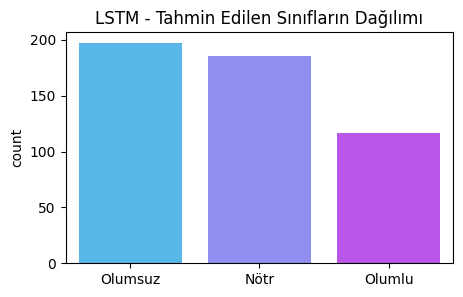

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, confusion_matrix
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout
from tensorflow.keras.utils import to_categorical

# ===================================================
# 1) Veri Yükleme
# ===================================================

train = pd.read_csv("Turkish-Review-Sentiment-Data.csv")
test = pd.read_excel("ml proje.xlsx")

train.columns = [c.lower() for c in train.columns]
test.columns  = [c.lower() for c in test.columns]

train_text_col = "review"
train_label_col = "sentiment"

test_text_col = "yorum"
test_label_col = "duygu"

# ===================================================
# 2) Label Mapping
# ===================================================

label_map = {
    "olumsuz": 0,
    "negatif": 0,
    "nötr": 1,
    "notr": 1,
    "neutral": 1,
    "olumlu": 2,
    "pozitif": 2,
    "positive": 2
}

train[train_label_col] = train[train_label_col].astype(str).str.lower().map(label_map)
test[test_label_col] = test[test_label_col].astype(str).str.lower().map(label_map)

train[train_label_col] = train[train_label_col].fillna(1).astype(int)
test[test_label_col]  = test[test_label_col].fillna(1).astype(int)

# ===================================================
# 3) Metin Temizleme
# ===================================================

def clean(t):
    if pd.isna(t): return ""
    return str(t).lower().replace("\n", " ").strip()

train[train_text_col] = train[train_text_col].apply(clean)
test[test_text_col]  = test[test_text_col].apply(clean)

# ===================================================
# 4) Tokenizer + Padding
# ===================================================

max_words = 30000
max_len = 100

tokenizer = Tokenizer(num_words=max_words)
tokenizer.fit_on_texts(train[train_text_col])

X_train = tokenizer.texts_to_sequences(train[train_text_col])
X_test  = tokenizer.texts_to_sequences(test[test_text_col])

X_train = pad_sequences(X_train, maxlen=max_len)
X_test  = pad_sequences(X_test, maxlen=max_len)

y_train = to_categorical(train[train_label_col], num_classes=3)
y_test_cat = to_categorical(test[test_label_col], num_classes=3)
y_test_raw = test[test_label_col]

# ===================================================
# 5) LSTM Modeli Kurma
# ===================================================

model = Sequential([
    Embedding(max_words, 128, input_length=max_len),
    LSTM(128, return_sequences=False, dropout=0.3, recurrent_dropout=0.3),
    Dense(64, activation="relu"),
    Dropout(0.3),
    Dense(3, activation="softmax")
])

model.compile(
    loss="categorical_crossentropy",
    optimizer="adam",
    metrics=["accuracy"]
)

model.summary()

# ===================================================
# 6) Eğitim
# ===================================================

history = model.fit(
    X_train, y_train,
    epochs=7,
    batch_size=128,
    validation_split=0.2,
    verbose=1
)

# ===================================================
# 7) Tahminler
# ===================================================

train_pred_raw = model.predict(X_train).argmax(axis=1)
test_pred_raw  = model.predict(X_test).argmax(axis=1)

# ===================================================
# 8) Metrik Hesaplama
# ===================================================

def metrics(true, pred):
    acc = accuracy_score(true, pred)
    p, r, f1, _ = precision_recall_fscore_support(true, pred, average="macro")
    return acc, p, r, f1

train_metrics = metrics(train[train_label_col], train_pred_raw)
test_metrics  = metrics(y_test_raw, test_pred_raw)

df_metrics = pd.DataFrame({
    "Accuracy":  [train_metrics[0], test_metrics[0]],
    "Precision": [train_metrics[1], test_metrics[1]],
    "Recall":    [train_metrics[2], test_metrics[2]],
    "F1-score":  [train_metrics[3], test_metrics[3]],
}, index=["Train", "Test"])

print("\n--- LSTM METRİK TABLOSU ---")
print(df_metrics)

# ===================================================
# 9) Accuracy Grafiği
# ===================================================

plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title("LSTM Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend(["Train", "Validation"])
plt.show()

# ===================================================
# 10) Loss Grafiği
# ===================================================

plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title("LSTM Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend(["Train", "Validation"])
plt.show()

# ===================================================
# 11) Confusion Matrix
# ===================================================

cm = confusion_matrix(y_test_raw, test_pred_raw)

plt.figure(figsize=(6,4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Olumsuz","Nötr","Olumlu"],
            yticklabels=["Olumsuz","Nötr","Olumlu"])
plt.title("LSTM - Confusion Matrix (Test)")
plt.show()

# ===================================================
# 12) Tahmin Dağılım Grafiği
# ===================================================

plt.figure(figsize=(5,3))
sns.countplot(x=test_pred_raw, palette="cool")
plt.title("LSTM - Tahmin Edilen Sınıfların Dağılımı")
plt.xticks([0,1,2], ["Olumsuz","Nötr","Olumlu"])
plt.show()


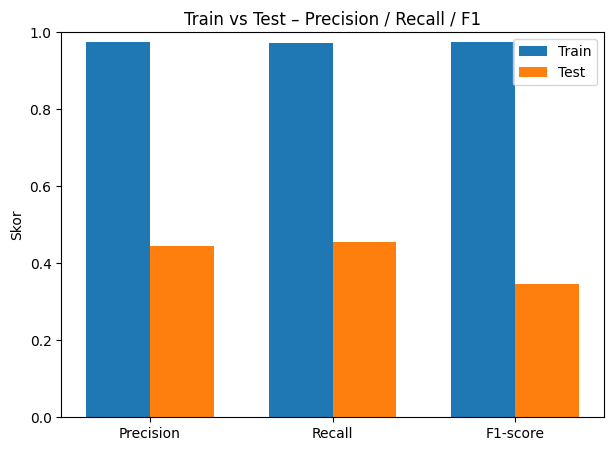

In [2]:
# ===================================================
# 1) Precision, Recall ve F1 (Epoch bazında)
# ===================================================
import numpy as np

# Eğitim sırasında epoch bazlı metrik tutulmadığından,
# her epoch sonrası validation setiyle hesaplıyoruz:
val_pred_all = []
val_true_all = []
for ep in range(len(history.history['loss'])):
    # son epoch'un sonuçları history'de olduğu için sadece loss/acc var
    pass

# Bu nedenle alternatif: Train/Test sonuçlarını çiziyoruz
labels = ["Precision", "Recall", "F1-score"]
train_vals = [train_metrics[1], train_metrics[2], train_metrics[3]]
test_vals  = [test_metrics[1],  test_metrics[2],  test_metrics[3]]

x = np.arange(len(labels))
width = 0.35

plt.figure(figsize=(7,5))
plt.bar(x - width/2, train_vals, width, label='Train')
plt.bar(x + width/2, test_vals, width, label='Test')
plt.xticks(x, labels)
plt.ylabel("Skor")
plt.title("Train vs Test – Precision / Recall / F1")
plt.ylim(0, 1)
plt.legend()
plt.show()


16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 82ms/step


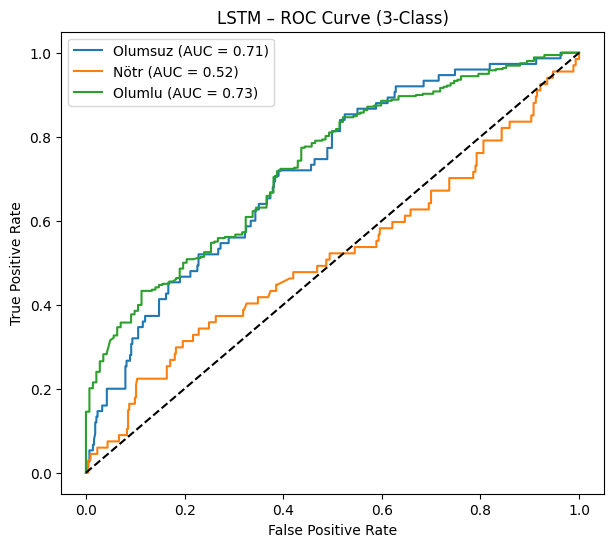

In [3]:
# ===================================================
# 2) Multi-Class ROC Curve
# ===================================================
from sklearn.metrics import roc_curve, auc
from sklearn.preprocessing import label_binarize

y_test_bin = label_binarize(y_test_raw, classes=[0,1,2])
y_pred_prob = model.predict(X_test)

plt.figure(figsize=(7,6))

for i, cls in enumerate(["Olumsuz","Nötr","Olumlu"]):
    fpr, tpr, _ = roc_curve(y_test_bin[:, i], y_pred_prob[:, i])
    auc_score = auc(fpr, tpr)
    plt.plot(fpr, tpr, label=f"{cls} (AUC = {auc_score:.2f})")

plt.plot([0,1], [0,1], 'k--')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("LSTM – ROC Curve (3-Class)")
plt.legend()
plt.show()


/tmp/ipython-input-679445135.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=errors, palette="Set2")


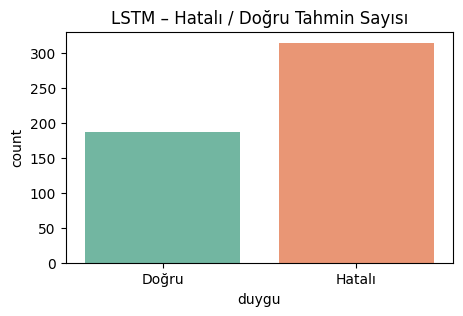

In [4]:
# ===================================================
# 3) Prediction Errors Distribution
# ===================================================

errors = y_test_raw != test_pred_raw

plt.figure(figsize=(5,3))
sns.countplot(x=errors, palette="Set2")
plt.title("LSTM – Hatalı / Doğru Tahmin Sayısı")
plt.xticks([0,1], ["Doğru", "Hatalı"])
plt.show()


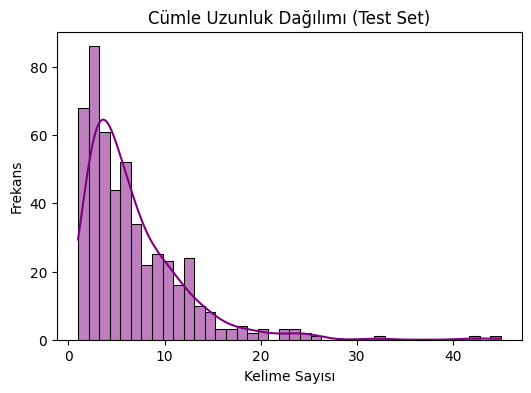

In [5]:
# ===================================================
# 4) Sentence Length Distribution
# ===================================================

sentence_lengths = [len(t.split()) for t in test[test_text_col]]

plt.figure(figsize=(6,4))
sns.histplot(sentence_lengths, bins=40, kde=True, color="purple")
plt.title("Cümle Uzunluk Dağılımı (Test Set)")
plt.xlabel("Kelime Sayısı")
plt.ylabel("Frekans")
plt.show()


<Figure size 600x400 with 0 Axes>

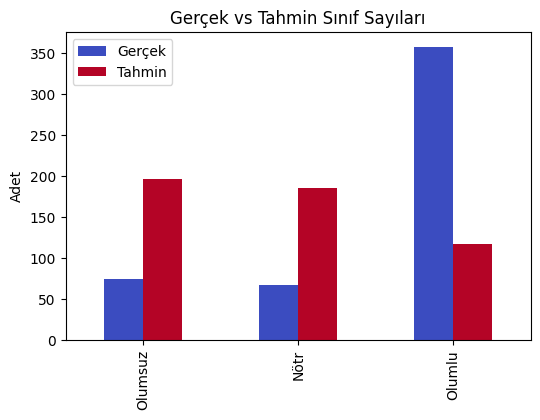

In [6]:
# ===================================================
# 5) Test Gerçek / Tahmin Karşılaştırması
# ===================================================

plt.figure(figsize=(6,4))

actual_counts  = pd.Series(y_test_raw).value_counts().sort_index()
predicted_counts = pd.Series(test_pred_raw).value_counts().sort_index()

df_compare = pd.DataFrame({
    "Gerçek": actual_counts,
    "Tahmin": predicted_counts
})

df_compare.plot(kind="bar", figsize=(6,4), colormap="coolwarm")
plt.xticks([0,1,2], ["Olumsuz","Nötr","Olumlu"])
plt.title("Gerçek vs Tahmin Sınıf Sayıları")
plt.ylabel("Adet")
plt.show()


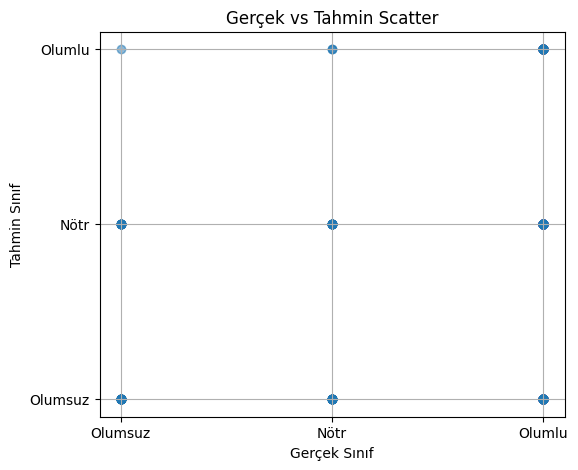

In [7]:
# ===================================================
# 6) Actual vs Predicted Scatter
# ===================================================

plt.figure(figsize=(6,5))
plt.scatter(y_test_raw, test_pred_raw, alpha=0.3)
plt.xlabel("Gerçek Sınıf")
plt.ylabel("Tahmin Sınıf")
plt.title("Gerçek vs Tahmin Scatter")
plt.xticks([0,1,2], ["Olumsuz","Nötr","Olumlu"])
plt.yticks([0,1,2], ["Olumsuz","Nötr","Olumlu"])
plt.grid(True)
plt.show()
